## A simulated day interview

In this notebook, the day interviewer agent (```src/cltl/demo_chatbot/day_interviewer.py```) talks to a **simulated user** instead of a real person. The simulated user plays the person of one of the example days in ```data/example_days```: an LLM answers the questions of the agent in the first person, using only the events of that day. Since we know the day of the simulated user, we can evaluate how well the agent reconstructs it: the example day is the GOLD description and the day collected by the agent is compared against it.

The notebook:

1. lets you select an example day
2. runs the conversation between the agent and the simulated user and shows it in a chat window
3. saves the collected day and the conversation
4. computes the statistics of the example day and the collected day
5. evaluates the collected day against the example day
6. converts the conversation to a CSV file in the format of the EMISSOR evaluation files and plots it

The code of the simulated user is in ```simulated_user.py``` in the same folder as this notebook.

### How the simulated user answers

The simulated user is an LLM that plays the person of the example day. It gets the facts of all the events of the day from the GOLD JSON (the times, what happened, who was there, what was used, where and how long), but not the words of the person in ```human_turn``` and, by default, not the ```description``` of the events, and answers each question of the agent naturally as that person, with the conversation so far. It knows nothing about the strategy of the agent and uses no techniques to interpret the questions: how well the agent understands the natural answers is part of what is evaluated.

The simulated user is not optimised to match the GOLD. In a real situation, the user does not know the GOLD and describes the day in their own words, so the agent has to match what it extracts with knowledge it does not know. The ```description``` of an event is a sentence written for the GOLD: a simulated user that repeats it would make the matching easier than with a real user. Set ```USE_DESCRIPTION = True``` to give it to the simulated user anyway, e.g. to compare the results. Lower scores without it show that the agent should be smarter and adapt to the user, not the other way around.

### Hour by hour or per part of the day

With ```PART_OF_DAY = True```, the agent does not ask hour by hour with follow-up questions, but only asks what the user did in the morning, in the afternoon and in the evening, and extracts all the activities from each answer (see the notebook of the day interviewer). This takes only a few turns, but the roles that the user does not mention stay empty, and events without a time only get the part of the day. In the evaluation, such an event can only be aligned if the GOLD event is in the same part of the day and its type and label match well. Compare the effectiveness of the communication of both strategies: the number of (correct) events and roles per turn.

### Avoiding endless conversations

The conversation ends when the agent is done, e.g. at the end of the day, or when the simulated user ends it itself. So that it cannot go on forever, ```stop``` is answered instead of the simulated user when:

* the agent has collected ```MAX_EVENTS``` events (20 by default, the number of events in the example days)
* the agent says the same thing 3 times in a row, e.g. when it does not understand an answer
* the conversation has ```MAX_TURNS``` turns

## Prerequisites

The agent and the simulated user both use the LLM of a local [llama.cpp](https://github.com/ggml-org/llama.cpp) server. Start the server in a terminal before running this notebook:

```bash
llama-server -hf Qwen/Qwen2.5-7B-Instruct-GGUF:Q4_K_M --port 8080 -c 4096
```

The notebook also needs the packages ```openai```, ```ipywidgets```, ```pandas```, ```scipy``` and ```matplotlib``` from the ```requirements.txt``` of the project.

In [1]:
import sys
from pathlib import Path

# Jupyter runs the notebook in its own folder. We add the root of the project to the path,
# so that the modules can be imported from src.cltl
PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "src" / "cltl").is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import json
import pandas as pd
import ipywidgets as widgets
from IPython.display import display
from openai import OpenAI

from src.cltl.simulated_user.simulated_user import simulate_day
from src.cltl.demo_chatbot.chat_window import ChatWindow
from src.cltl.demo_chatbot.day_statistics import save_day_statistics, get_events
from src.cltl.task_evaluation.day_evaluation import evaluate_files, save_turn_evaluation, EVENT_THRESHOLD
from src.cltl.emissor_evaluation.plots import plot_interaction as plot

## Settings

* ```LLAMA_CPP_URL```: the address of the llama.cpp server
* ```EXAMPLE_DAYS```: the folder with the example days
* ```OUTPUT```: the folder in which the collected days and the conversations are saved. The default ```data/simulated_days``` keeps them apart from the days collected from real users in ```data/collected_days```.
* ```MAX_EVENTS``` and ```MAX_TURNS```: the conversation stops when the agent has collected this number of events or after this number of turns
* ```FONT_SIZE```: the font size of the chat window, which can also be changed with the slider in the window
* ```EVENT_THRESHOLD```: the minimal similarity to align a collected event with an event of the example day in the evaluation
* ```MAX_GOLD_EVENTS```: only evaluate the first events of the example day: ```None``` for all events, a number, or ```"collected"``` for as many as the agent collected, e.g. when the conversation stopped at ```MAX_EVENTS``` or was interrupted. The cut is made on the order of the GOLD events, not on the time.
* ```PART_OF_DAY```: with ```True```, the agent asks once for the morning, the afternoon and the evening instead of hour by hour. ```False``` by default.
* ```USE_DESCRIPTION```: with ```True```, the simulated user also knows the descriptions of the events in the example day, which makes its answers closer to the GOLD than the answers of a real user. ```False``` by default.

In [16]:
LLAMA_CPP_URL = "http://localhost:8080/v1"
EXAMPLE_DAYS = PROJECT_ROOT / "data" / "example_days"
OUTPUT = PROJECT_ROOT / "data" / "simulated_days"
MAX_EVENTS = 20
MAX_TURNS = 400
FONT_SIZE = 16
USE_DESCRIPTION = False
PART_OF_DAY = False # hour by hour
PART_OF_DAY = True # morning, afternoon, evening
MAX_GOLD_EVENTS = None

In [17]:
llama_client = OpenAI(base_url=LLAMA_CPP_URL, api_key="sk-no-key-required")

# llama.cpp serves the model it was started with, the name is only used for reporting
model = llama_client.models.list().data[0].id
print('Model served by llama.cpp:', model)

Model served by llama.cpp: Qwen/Qwen2.5-7B-Instruct-GGUF:Q4_K_M


## Selecting an example day

Select the example day that the simulated user will tell about, then run the next cells.

In [18]:
example_days = sorted(path.name for path in EXAMPLE_DAYS.glob("*.json") if not path.stem.endswith("_meta"))
day_selector = widgets.Dropdown(options=example_days, value=example_days[0], description="Example day")
day_selector

Dropdown(description='Example day', options=('day1_emma_student.json', 'day2_daan_nurse.json', 'day3_henk_reti…

## The conversation

The next cell runs the conversation and shows it in the chat window: the agent on the left and the simulated user on the right. A conversation with 20 events takes a few minutes, since each answer needs the LLM. To stop the conversation earlier, interrupt the kernel: the collected day is then saved with the events so far.

The collected day is saved as ```day_<name>_<strategy>_<date>.json``` (```<strategy>``` is ```hour_by_hour``` or ```part_of_day```) in ```OUTPUT``` and the conversation as ```day_<name>_<strategy>_<date>_conversation.csv``` next to it.

In [19]:
KEY = EXAMPLE_DAYS / day_selector.value
print("Example day:", KEY)

window = ChatWindow(None, font_size=FONT_SIZE)
window.show_conversation()
agent, user, conversation = simulate_day(llama_client, model, KEY, output_folder=OUTPUT, max_events=MAX_EVENTS,
                                         max_turns=MAX_TURNS, on_turn=window.add_message,
                                         use_description=USE_DESCRIPTION, part_of_day=PART_OF_DAY)

COLLECTED = Path(agent.path)
print(f"{len(conversation)} turns, {len(agent.day)} events")
print("Collected day:", COLLECTED)

Example day: /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/example_days/day1_emma_student.json


13 turns, 13 events
Collected day: /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/simulated_days/day_emma_part_of_day_20261022_1211.json


The questions of the agent and the answers of the simulated user for each collected event, as saved in ```agent_turn``` and ```human_turn```:

In [20]:
for key, event in agent.day.items():
    # per part of the day, an event without a time has only the part of the day and no how_long
    duration = f" for {event['how_long']} minutes" if event["how_long"] else ""
    print(f"{key}: {event['event_label']} at {event['when'][0]}{duration}")
    for question, answer in zip(event["agent_turn"], event["human_turn"]):
        print(f"    {question['turn_id']:>3} Agent:", question["utterance"])
        print(f"    {answer['turn_id']:>3} {user.name}:", answer["utterance"] or "(skipped)")

event1: wake up at 07:30
      7 Agent: What did you do in the morning?
      8 Emma: In the morning, I woke up at 07:30 to my phone alarm. Then I had a quick shower from 07:40 to 08:00. After that, I had breakfast with my flatmate Lotte from 08:00 to 08:20. We had yoghurt, granola, and coffee.
event2: shower at 07:40 for 20 minutes
      7 Agent: What did you do in the morning?
      8 Emma: In the morning, I woke up at 07:30 to my phone alarm. Then I had a quick shower from 07:40 to 08:00. After that, I had breakfast with my flatmate Lotte from 08:00 to 08:20. We had yoghurt, granola, and coffee.
event3: breakfast at 08:00 for 20 minutes
      7 Agent: What did you do in the morning?
      8 Emma: In the morning, I woke up at 07:30 to my phone alarm. Then I had a quick shower from 07:40 to 08:00. After that, I had breakfast with my flatmate Lotte from 08:00 to 08:20. We had yoghurt, granola, and coffee.
event4: cycling to the university at 08:25
      9 Agent: What did you do in the 

## Statistics of the example day and the collected day

```save_day_statistics``` computes the statistics of a day and saves them next to the day as ```<name>_meta.json```.

In [21]:
key_meta, key_statistics = save_day_statistics(str(KEY))
collected_meta, collected_statistics = save_day_statistics(str(COLLECTED))
print("Saved", key_meta)
print("Saved", collected_meta)

counts = ["nr_of_events", "nr_of_roles", "nr_of_roles_from_photos", "nr_of_coreference_chains",
          "average_nr_of_mentions_per_chain", "nr_of_unique_what", "nr_of_unique_with_what"]
display(pd.DataFrame({"example day": {count: key_statistics.get(count) for count in counts},
                      "collected": {count: collected_statistics.get(count) for count in counts}}))
display(pd.DataFrame({"example day": key_statistics["nr_of_roles_per_role"],
                      "collected": collected_statistics["nr_of_roles_per_role"]}))

Saved /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/example_days/day1_emma_student_meta.json
Saved /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/simulated_days/day_emma_part_of_day_20261022_1211_meta.json


,example day,collected
nr_of_events,20.00,13.00
nr_of_roles,127.00,65.00
nr_of_roles_from_photos,5.00,0.00
nr_of_coreference_chains,14.00,8.00
average_nr_of_mentions_per_chain,2.79,2.88
nr_of_unique_what,22.00,6.00
nr_of_unique_with_what,34.00,3.00


,example day,collected
who,20,13
what,15,4
with_what,20,4
with_whom,12,7
where,20,13
when,20,13
how_long,20,11


## Evaluation

The collected day is evaluated against the example day on three levels: **events**, **roles** (is the role filled?) and **role-fillers** (do the values match?), each with the true positives, false positives, false negatives, true negatives (only for roles) and the precision, recall and f1. The values are compared with an **exact** match and with a **jaccard** match of the words. In both modes, ```where``` and ```when``` are weighted by the specificity of the match and ```who``` and ```with_whom``` are matched through the coreference chains. See ```src/cltl/task_evaluation/day_evaluation.py``` for the details.

In [22]:
evaluation = evaluate_files(str(KEY), str(COLLECTED), event_threshold=EVENT_THRESHOLD, verbose=False,
                            max_gold_events=MAX_GOLD_EVENTS)
print("Saved", evaluation["output"])
print(f"Evaluated {evaluation['nr_of_gold_events']} GOLD events")

COLUMNS = ["tp", "fp", "fn", "tn", "precision", "recall", "f1"]
rows = {}
for mode, results in evaluation["modes"].items():
    rows[(mode, "events")] = results["events"]
    rows[(mode, "roles")] = results["roles"]["total"]
    rows[(mode, "role-fillers")] = results["role_fillers"]["total"]
pd.DataFrame(rows).T[COLUMNS]

Saved /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/simulated_days/day_emma_part_of_day_20261022_1211_vs_day1_emma_student_evaluation.json
Evaluated 20 GOLD events


tp      fp       fn   tn  precision  recall     f1
exact   events        12.000   1.000    8.000  NaN      0.923   0.600  0.727
        roles         61.000   4.000   66.000  7.0      0.938   0.480  0.635
        role-fillers  54.076  16.924  110.924  NaN      0.762   0.328  0.458
jaccard events        13.000   0.000    7.000  NaN      1.000   0.650  0.788
        roles         65.000   0.000   62.000  9.0      1.000   0.512  0.677
        role-fillers  60.446  10.554  104.554  NaN      0.851   0.366  0.512

The roles and role-fillers per role, for both modes:

In [23]:
for mode, results in evaluation["modes"].items():
    print(f"Mode: {mode}")
    display(pd.DataFrame(results["roles"]).T[COLUMNS])
    display(pd.DataFrame(results["role_fillers"]).T[COLUMNS])

Mode: exact


,tp,fp,fn,tn,precision,recall,f1
total,61.0,4.0,66.0,7.0,0.938,0.480,0.635
who,12.0,1.0,8.0,0.0,0.923,0.600,0.727
what,4.0,0.0,11.0,3.0,1.000,0.267,0.421
with_what,3.0,1.0,17.0,0.0,0.750,0.150,0.250
with_whom,7.0,0.0,5.0,4.0,1.000,0.583,0.737
where,12.0,1.0,8.0,0.0,0.923,0.600,0.727
when,12.0,1.0,8.0,0.0,0.923,0.600,0.727
how_long,11.0,0.0,9.0,0.0,1.000,0.550,0.710


,tp,fp,fn,tn,precision,recall,f1
total,54.076,16.924,110.924,NaN,0.762,0.328,0.458
who,12.000,1.000,8.000,NaN,0.923,0.600,0.727
what,5.000,2.000,20.000,NaN,0.714,0.200,0.312
with_what,1.000,3.000,40.000,NaN,0.250,0.024,0.044
with_whom,8.000,2.000,11.000,NaN,0.800,0.421,0.552
where,6.476,6.524,13.524,NaN,0.498,0.324,0.392
when,11.600,1.400,8.400,NaN,0.892,0.580,0.703
how_long,10.000,1.000,10.000,NaN,0.909,0.500,0.645


Mode: jaccard


,tp,fp,fn,tn,precision,recall,f1
total,65.0,0.0,62.0,9.0,1.0,0.512,0.677
who,13.0,0.0,7.0,0.0,1.0,0.650,0.788
what,4.0,0.0,11.0,4.0,1.0,0.267,0.421
with_what,4.0,0.0,16.0,0.0,1.0,0.200,0.333
with_whom,7.0,0.0,5.0,5.0,1.0,0.583,0.737
where,13.0,0.0,7.0,0.0,1.0,0.650,0.788
when,13.0,0.0,7.0,0.0,1.0,0.650,0.788
how_long,11.0,0.0,9.0,0.0,1.0,0.550,0.710


,tp,fp,fn,tn,precision,recall,f1
total,60.446,10.554,104.554,NaN,0.851,0.366,0.512
who,13.000,0.000,7.000,NaN,1.000,0.650,0.788
what,5.000,2.000,20.000,NaN,0.714,0.200,0.312
with_what,2.500,1.500,38.500,NaN,0.625,0.061,0.111
with_whom,9.000,1.000,10.000,NaN,0.900,0.474,0.621
where,7.457,5.543,12.543,NaN,0.574,0.373,0.452
when,12.600,0.400,7.400,NaN,0.969,0.630,0.764
how_long,10.889,0.111,9.111,NaN,0.990,0.544,0.703


The events of the example day that are aligned with the collected events (jaccard mode), and the events that are missed or added:

In [24]:
MODE = "jaccard"
alignment = pd.DataFrame(evaluation["modes"][MODE]["event_alignment"])
display(alignment)

key_events = get_events(json.load(open(KEY)))
collected_events = get_events(json.load(open(COLLECTED)))
aligned_key = set(alignment["gold"]) if len(alignment) else set()
aligned_collected = set(alignment["system"]) if len(alignment) else set()

def event_rows(events, aligned):
    return pd.DataFrame([{"event": key, "event_label": event["event_label"], "when": event["when"][0],
                          "how_long": event["how_long"]}
                         for key, event in events.items() if key not in aligned])

print("Missed events of the example day")
display(event_rows(key_events, aligned_key))
print("Collected events that are not in the example day")
display(event_rows(collected_events, aligned_collected))

,gold,system,similarity,gold_label,system_label,comment
0,event1,event1,0.833,waking up,wake up,similarity = 0.5 * time 1.00 + 0.25 * type 1.0...
1,event2,event2,0.750,showering,shower,similarity = 0.5 * time 1.00 + 0.25 * type 1.0...
2,event3,event3,1.000,breakfast,breakfast,similarity = 0.5 * time 1.00 + 0.25 * type 1.0...
3,event4,event4,0.750,cycling to university,cycling to the university,similarity = 0.5 * time 1.00 + 0.25 * type 0.0...
4,event5,event5,1.000,attending lecture,attending a lecture,similarity = 0.5 * time 1.00 + 0.25 * type 1.0...
5,event6,event6,0.750,coffee break,coffee break,similarity = 0.5 * time 1.00 + 0.25 * type 0.0...
6,event7,event7,1.000,group project meeting,group project meeting,similarity = 0.5 * time 1.00 + 0.25 * type 1.0...
7,event8,event8,1.000,lunch,lunch,similarity = 0.5 * time 1.00 + 0.25 * type 1.0...
8,event9,event9,0.750,signing an internship contract,signing an internship contract,similarity = 0.5 * time 1.00 + 0.25 * type 0.0...
9,event10,event10,0.750,calling parents,video call,similarity = 0.5 * time 1.00 + 0.25 * type 1.0...


Missed events of the example day


,event,event_label,when,how_long
0,event12,cycling to the supermarket,15:50,15
1,event15,cooking dinner,18:15,40
2,event16,celebratory dinner,19:00,60
3,event17,doing the dishes,20:00,20
4,event18,watching a series,20:30,90
5,event19,messaging friends,22:05,25
6,event20,going to sleep,22:40,480


Collected events that are not in the example day


""


## The conversation as an EMISSOR CSV file

```save_turn_evaluation``` converts the conversation of the collected events to a CSV file in the format of the evaluation files of the EMISSOR scenarios: a row for each question of the agent and each answer of the simulated user, with the columns ```Turn```, ```Speaker``` and ```Response```. When several events were extracted from one answer, as with ```PART_OF_DAY = True```, the turn has one row with the numbers of all these events. The rows of the user have the number of events and roles extracted from the turn and the number of correct events and roles in both modes. The file is saved as ```<collected>_vs_<example day>_turn_evaluation.csv``` next to the collected day.

The full conversation, including the questions about the name and the hour at which the day started and the skipped hours, was already saved as ```<collected>_conversation.csv```.

In [25]:
turn_csv = save_turn_evaluation(str(KEY), str(COLLECTED), event_threshold=EVENT_THRESHOLD,
                                max_gold_events=MAX_GOLD_EVENTS)
print("Saved", turn_csv)
pd.read_csv(turn_csv, sep=";").head(20)


Effectiveness of the communication: 6 turns (3 agent, 3 user)
                                 total  per user turn  per turn
nr_of_events                        13          4.333     2.167
nr_of_roles                         65         21.667    10.833
nr_of_correct_events_exact          12          4.000     2.000
nr_of_correct_events_jaccard        13          4.333     2.167
nr_of_correct_roles_exact       48.077         16.026     8.013
nr_of_correct_roles_jaccard     54.446         18.149     9.074
Saved the effectiveness to /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/simulated_days/day_emma_part_of_day_20261022_1211_vs_day1_emma_student_turn_effectiveness.json
Saved /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/simulated_days/day_emma_part_of_day_20261022_1211_vs_day1_emma_student_turn_evaluation.csv


,Turn,Turn nr.,Speaker,Response,Event,nr_of_events,nr_of_roles,nr_of_correct_events_exact,nr_of_correct_events_jaccard,nr_of_correct_roles_exact,nr_of_correct_roles_jaccard
0,turn7,0,AGENT,What did you do in the morning?,"event1,event2,event3",NaN,NaN,NaN,NaN,NaN,NaN
1,turn8,1,Emma,"In the morning, I woke up at 07:30 to my phone...","event1,event2,event3",3.0,15.0,3.0,3.0,13.000,13.643
2,turn9,2,AGENT,What did you do in the afternoon?,"event4,event5,event6,event7,event8",NaN,NaN,NaN,NaN,NaN,NaN
3,turn10,3,Emma,"In the afternoon, I cycled to the university a...","event4,event5,event6,event7,event8",5.0,25.0,4.0,5.0,16.787,21.513
4,turn11,4,AGENT,What did you do in the evening?,"event9,event10,event11,event12,event13",NaN,NaN,NaN,NaN,NaN,NaN
5,turn12,5,Emma,"In the evening, I signed an internship contrac...","event9,event10,event11,event12,event13",5.0,25.0,5.0,5.0,18.290,19.290


## Plotting the conversation

The CSV file can be plotted with the ```plots``` module, like the CSV files of the EMISSOR analyses. Each turn is shown on the X-axis. The first plot shows two lines: the number of events and the number of roles extracted from each answer of the user. The second plot shows the number of correct events and correct roles (jaccard mode). The questions of the agent are shown on the X-axis, but have no points, since the agent does not extract anything itself. ```create_timeline_image_from_csv_columns``` can plot any columns of the CSV file together in this way. The plots are saved next to the CSV file. A conversation of 20 events has more than a hundred turns, so the plots are wide: scroll horizontally to see all turns, or set ```settings._START``` and ```settings._END``` to plot a part of the conversation, e.g. the turns 0 to 40.

Nr of turns 6
Nr of turns 6
Saved plot to /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/simulated_days/day_emma_part_of_day_20261022_1211_vs_day1_emma_student_turn_evaluation_extracted_plot.png



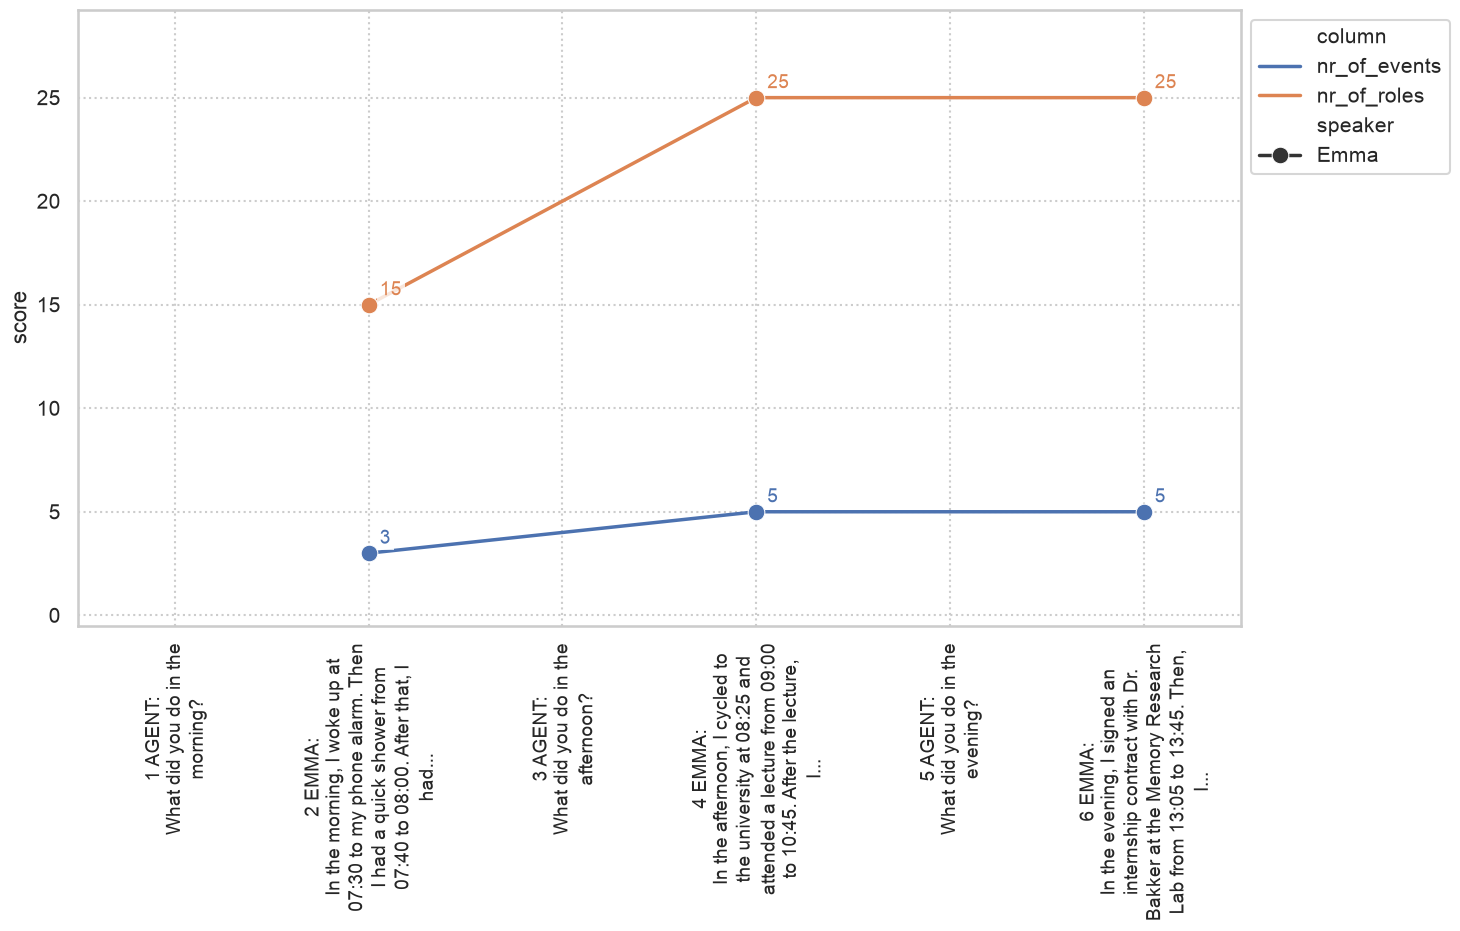

In [26]:
settings = plot.PlotSettings()
plot_file = plot.create_timeline_image_from_csv_columns(turn_csv, ["nr_of_events", "nr_of_roles"], settings,
                                                        name="extracted")

Nr of turns 6
Nr of turns 6
Saved plot to /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/simulated_days/day_emma_part_of_day_20261022_1211_vs_day1_emma_student_turn_evaluation_correct_jaccard_plot.png



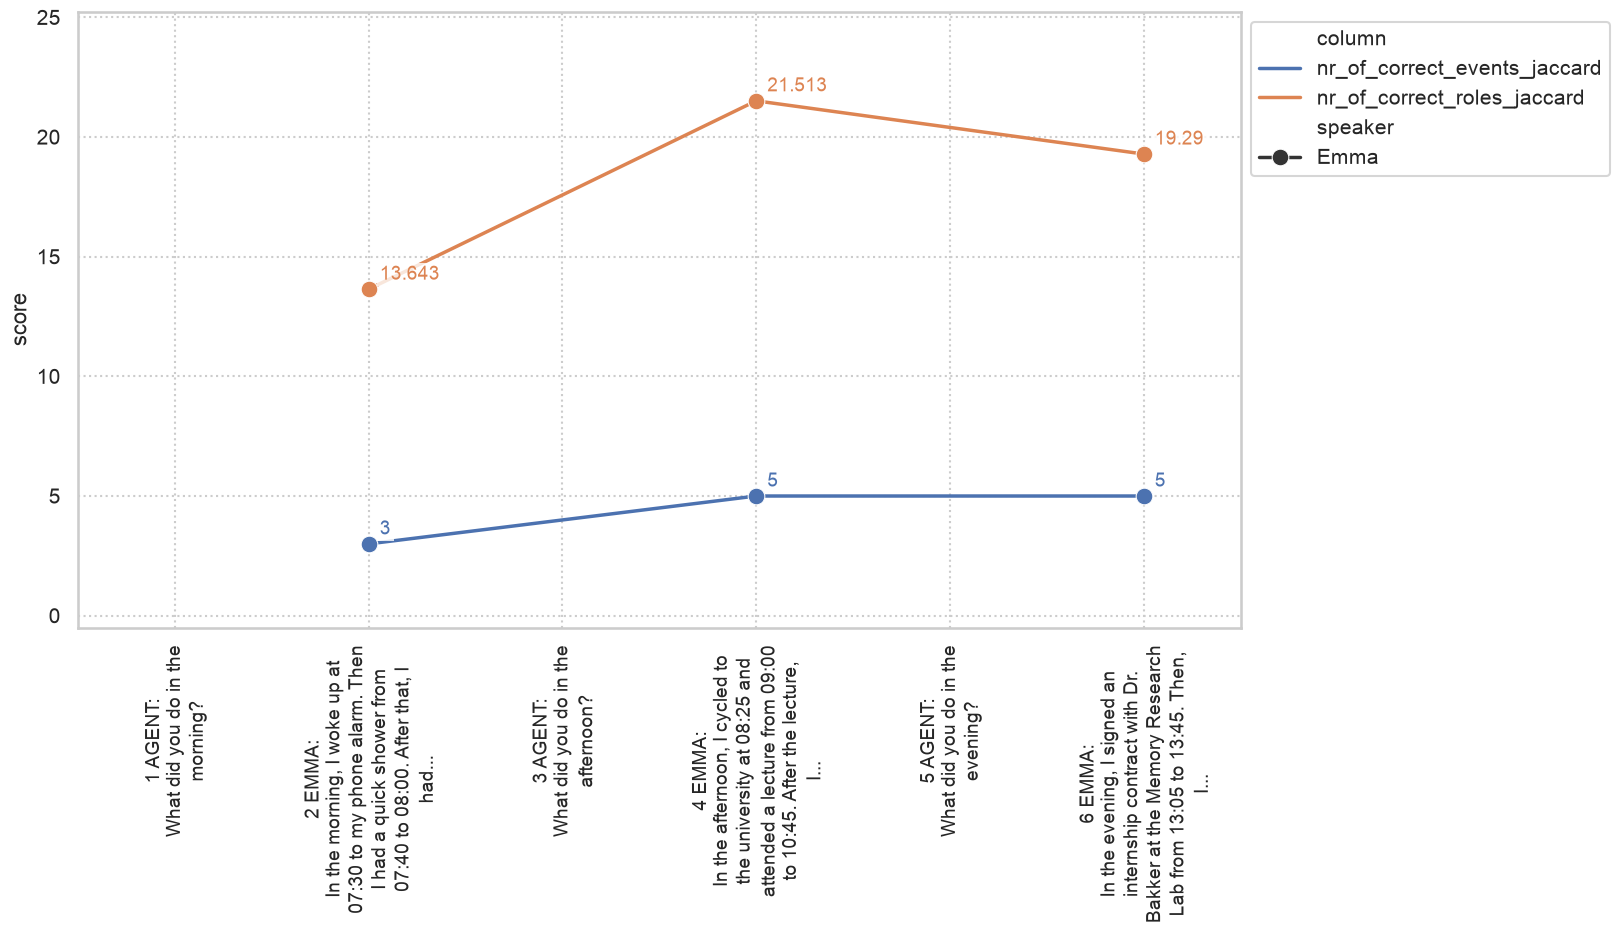

In [27]:
plot_file = plot.create_timeline_image_from_csv_columns(
    turn_csv, ["nr_of_correct_events_jaccard", "nr_of_correct_roles_jaccard"], settings, name="correct_jaccard")